
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/13_Lab_PinnsII.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pylab as plt
import plotly.graph_objects as go

La **diferenciación automática** calcula derivadas exactas sin derivar la fórmula completa a mano.

Cada cantidad se representa como una pareja **(valor, derivada)**:
- la variable $x$ entra como $(x,\ 1)$, porque $\frac{dx}{dx}=1$;
- una constante $c$ entra como $(c,\ 0)$, porque no cambia.

Cada operación recibe parejas y devuelve una nueva pareja. Al encadenar operaciones, la **regla de la cadena** se aplica sola.

### Reglas de derivación para cada operación

| Función | Valor | Derivada |
|---|---|---|
| `suma(a, da, b, db)` | $a+b$ | $a'+b'$ |
| `producto(a, da, b, db)` | $a\,b$ | $a\,b' + a'\,b$ |
| `division(a, da, b, db)` | $a/b$ | $\dfrac{b\,a' - a\,b'}{b^2}$ |
| `seno(a, da)` | $\sin a$ | $\cos(a)\cdot a'$ |
| `coseno(a, da)` | $\cos a$ | $-\sin(a)\cdot a'$ |
| `tanhiperbolica(a, da)` | $\tanh a$ | $(1-\tanh^2 a)\cdot a'$ |

El factor $\cdot\,a'$ de la columna de derivadas **es la regla de la cadena**: la derivada local se multiplica por la derivada que ya traía la entrada.

**Ejemplo** con $x = 2$: `producto(x, 1, x, 1)` representa $x^2$ y devuelve $(4,\ 4)$, porque $2\cdot1 + 1\cdot2 = 4 = 2x$.

In [2]:
def suma(a, da, b, db):
  return a+b, da+db

def producto(a, da, b, db):
  return a*b, a*db + da*b

def division(a, da, b, db):
  return a/b, (b*da - a*db)/(b**2)

def seno(a, da):
  return np.sin(a), da*np.cos(a)

def coseno(a, da):
  return np.cos(a), -da*np.sin(a)


def tanhiperbolica(a, da):
    valor = np.tanh(a)
    return valor, (1 - valor**2)*da


def tanhiperbolica2(a, da, d2a):
    A, dA = tanhiperbolica(a, da)
    A2, dA2 = producto(A, dA, A, dA)
    G, dG = suma(1, 0, -A2, -dA2)
    _, d2A = producto(G, dG, da, d2a)
    return A, dA, d2A

Computemos la deriva de:

$f(x) = x^2$ en $x=3$

In [25]:

x, dx = 3, 1
f, df = producto(x,1,x,1)
print(f,df)


9 6


$f(x) = (2x+1)^2$ en $x=1$

In [19]:
x = np.linspace(-3, 3, 100)
#x, dx = 1, 1
u, du = producto(2,0,x,1)
c, dc = suma(u, du, 1, 0)
f, df = producto(c, dc, c, dc)
#print(f,df) # En x =1 > (9,12)

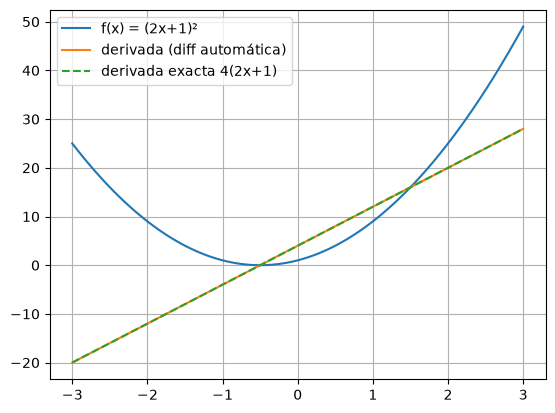

In [17]:
plt.plot(x, f,  label="f(x) = (2x+1)²")
plt.plot(x, df, label="derivada (diff automática)")
plt.plot(x, 4*(2*x + 1), "--", label="derivada exacta 4(2x+1)")
plt.legend()
plt.grid()
plt.show()

$f(x) = (3x+2)^2$ en $x=1$

In [27]:
x = np.linspace(-3, 3, 100)
#x, dx = 1, 1
u, du = producto(3, 0, x, 1)
c, dc = suma(u, du, 2, 0)
f, df = producto(c, dc, c, dc)
#print(f,df)
# En x=1 > (25,30)

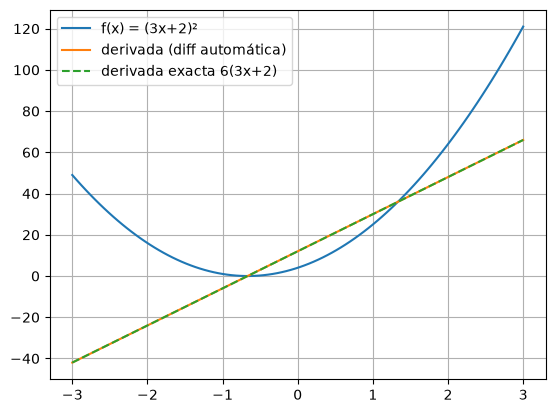

In [29]:
plt.plot(x, f,  label="f(x) = (3x+2)²")
plt.plot(x, df, label="derivada (diff automática)")
plt.plot(x, 6*(3*x + 2), "--", label="derivada exacta 6(3x+2)")
plt.legend()
plt.grid()
plt.show()

$
f(x)=\sin\!\bigl(\cos(x^2)\bigr),
$

$
u=x^2,\qquad u'=2x,
$

$
v=\cos(u),\qquad v'=-\sin(u)\,u',
$


$
f=\sin(v),\qquad f'=\cos(v)\,v'.
$


$
f'(x)=-2x\,\sin(x^2)\,\cos\!\bigl(\cos(x^2)\bigr).
$

In [30]:
x = np.linspace(0, 2*np.pi, 10000)
u, du = producto(x, 1, x, 1)
c, dc = coseno(u, du)
f, df = seno(c, dc)

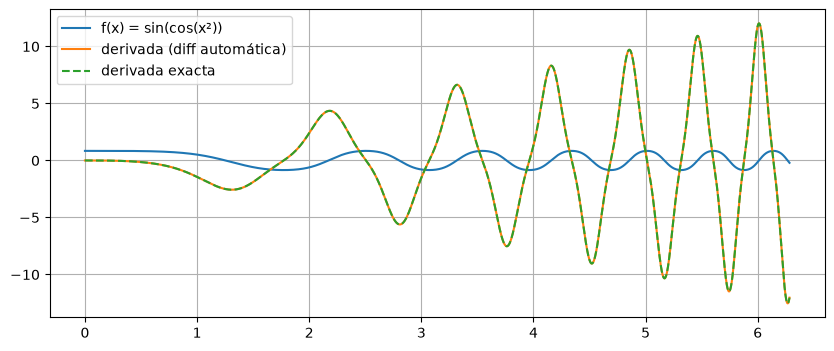

In [31]:
plt.figure(figsize=(10, 4))
plt.plot(x, f,  label="f(x) = sin(cos(x²))")
plt.plot(x, df, label="derivada (diff automática)")
plt.plot(x, -2*x*np.sin(x**2)*np.cos(np.cos(x**2)), "--",
         label="derivada exacta")
plt.legend()
plt.grid()
plt.show()

Supongamos que tenemos dos neuronas conectadas y queremos computar una diferenciacion automática cuyas funciones de activación son tanh:

\begin{equation}
\frac{da_2}{dx}
=
\frac{da_2}{dz_2}
\frac{dz_2}{da_1}
\frac{da_1}{dz_1}
\frac{dz_1}{dx}
=
(1-\tanh Z_2^2)\,w_2\,(1-\tanh Z_1^2)\,w_1.
\end{equation}



#### Forma 1: usando la fórmula escrita a mano

Primero calculamos la red normalmente (forward), guardando los valores intermedios $z_1$, $a_1$, $z_2$ y $a_2$.

Luego aplicamos directamente la fórmula de la regla de la cadena:

$$\frac{da_2}{dx} = (1-\tanh^2 z_2)\, (1-\tanh^2 z_1)\, w^2$$

Aparece $w^2$ porque las dos neuronas usan el mismo peso $w$, y la cadena lo multiplica dos veces.

**Desventaja:** hay que deducir la fórmula a mano. Con más neuronas o capas, esto se vuelve imposible.

In [32]:
x = 0.8
w = 0.1
b = 0.1

z = w*x + b
a1 = np.tanh(z)

z2 = w*a1 + b
a2 = np.tanh(z2)

derivada = (1-(np.tanh( z2))**2) * (1-(np.tanh( z))**2)*w**2
derivada

np.float64(0.009549719627467191)

#### Forma 2: usando diferenciación automática

Ahora no escribimos ninguna fórmula de derivada. Cada operación recibe y devuelve la pareja (valor, derivada):

| Paso | Operación | Código | Pareja |
|---|---|---|---|
| 1 | $t_1 = w\cdot x$ | `producto(w, 0, x, 1)` | $(0.08,\ 0.1)$ |
| 2 | $z_1 = t_1 + b$ | `suma(t1, dt1, b, 0)` | $(0.18,\ 0.1)$ |
| 3 | $a_1 = \tanh z_1$ | `tanhiperbolica(z, dz)` | $(0.17808,\ 0.096829)$ |
| 4 | $t_2 = w\cdot a_1$ | `producto(w, 0, a1, da1)` | $(0.017808,\ 0.0096829)$ |
| 5 | $z_2 = t_2 + b$ | `suma(t2, dt2, b, 0)` | $(0.11781,\ 0.0096829)$ |
| 6 | $a_2 = \tanh z_2$ | `tanhiperbolica(z2, dz2)` | $(0.11727,\ 0.0095497)$ |

- $x$ entra con derivada 1 porque es la variable respecto a la que derivamos.
- $w$ y $b$ entran con derivada 0 porque aquí son constantes: no derivamos respecto a ellos.
- La operación $w x + b$ se divide en dos pasos (un producto y luego una suma) porque cada función hace solo una operación.

El resultado `da2` debe coincidir con el de la Forma 1: $\approx 0.0095497$.

In [35]:
t1, dt1 = producto(w, 0, x, 1)
z, dz = suma(t1, dt1, b, 0)
a1, da1 = tanhiperbolica(z, dz)

t2, dt2 = producto(w, 0, a1, da1)
z2, dz2 = suma(t2, dt2, b, 0)
a2, da2 = tanhiperbolica(z2, dz2)
a2, da2

(np.float64(0.11726608605144122), np.float64(0.009549719627467191))

#### Forma 3: empaquetando una neurona en una función

Los tres pasos de una neurona (producto, suma y tanh) se repiten en cada capa, por tanto se pueden agrupar en una función `dneurona`.

- **Entrada:** la pareja $(x,\ dx)$ y los parámetros $w$, $b$.
- **Salida:** la pareja $(a,\ da)$ con la activación y su derivada.

Se usa `dx` en lugar de `1` para poder **encadenar neuronas**: la segunda neurona recibe como entrada la pareja $(a_1,\ da_1)$ que produjo la primera.

In [36]:
def dneurona(x, dx, w, b):
  t1, dt1 = producto(w, 0, x, dx)
  z, dz = suma(t1, dt1, b, 0)
  a1, da1 = tanhiperbolica(z, dz)
  return a1, da1

In [37]:
a1, da1 = dneurona(x, 1, w, b)
a2, da2 = dneurona(a1, da1, w, b)
a2, da2

(np.float64(0.11726608605144122), np.float64(0.009549719627467191))

### Difusión de calor en una placa cuadrada

Considere una placa homogénea de lado $L$, sin fuentes internas
de calor y con temperatura uniforme a través de su espesor.
Su difusividad térmica es constante:

$$
\alpha=\frac{k}{\rho c_p},
$$

donde $k$ es la conductividad térmica, $\rho$ la densidad y
$c_p$ el calor específico.

Determine la temperatura $T(x,y,t)$ en el dominio
$(x,y)\in(0,L)^2$, para $t>0$, mediante la ecuación de calor:

$$
\frac{\partial T}{\partial t}
=
\alpha\left(
\frac{\partial^2T}{\partial x^2}
+
\frac{\partial^2T}{\partial y^2}
\right).
$$

Los cuatro bordes permanecen a temperatura constante $T_b$:

$$
T(0,y,t)=T(L,y,t)=T(x,0,t)=T(x,L,t)=T_b.
$$

La temperatura inicial es:

$$
T(x,y,0)=T_b+\Delta T
\sin\left(\frac{\pi x}{L}\right)
\sin\left(\frac{\pi y}{L}\right),
$$

donde $\Delta T>0$ es la diferencia inicial entre la temperatura
del centro y la de los bordes.

Aproximar $T(x,y,t)$ mediante una PINN,
minimizando el residual de la ecuación y los errores en las
condiciones iniciales y de frontera. Comparar el resultado
con la solución analítica:

$$
T(x,y,t)=T_b+\Delta T
e^{-2\alpha\pi^2t/L^2}
\sin\left(\frac{\pi x}{L}\right)
\sin\left(\frac{\pi y}{L}\right).
$$

In [38]:
Lx = 1.0       # Longitud en x [m]
Ly = 1.0       # Longitud en y [m]
Tb = 300     # Temperatura fija de los bordes [°C]
delta_T = 100.0 # Diferencia inicial centro-bordes [°C]

alpha = 1e-4  # Difusividad térmica [m²/s]
params = {'Lx': Lx, 'Ly': Ly, 'Tb': Tb, "delta":delta_T ,'alpha': alpha}

In [ ]:
# Implementación de la solucion analítica
def T(x, y, t, **params):

  Lx = params['Lx']
  Ly = params['Ly']
  Tb = params['Tb']
  alpha = params['alpha']
  u = np.sin(np.pi*x/Lx)*np.sin(np.pi*y/Ly)
  return Tb + delta_T* np.exp(-2*alpha*np.pi**2*t/(Lx*Ly))*u


### Discretización del espacio y del tiempo

Definimos los puntos donde calcularemos la temperatura:

- **Espacio:** una malla de $30\times30$ puntos sobre la placa, separados $dx = dy = 1/29 \approx 0.0345$ m.
- **Tiempo:** el paso máximo para que un esquema explícito (Euler) sea estable es
$$
\Delta t_{max} = \frac{1}{2\alpha\left(\frac{1}{\Delta x^2}+\frac{1}{\Delta y^2}\right)} \approx 2.97 \text{ s}.
$$
  Usamos el 90 % de ese valor como margen de seguridad, lo que da $n_t = 188$ instantes entre 0 y 500 s ($\Delta t \approx 2.67$ s).

`np.meshgrid` construye las coordenadas $(X, Y)$ de cada punto de la placa, y `Temperatura` es un arreglo de forma $(n_t, n_x, n_y) = (188, 30, 30)$: una "foto" de la placa en cada instante.

In [40]:
nx, ny = 30, 30
tiempo_final = 500.0

x = np.linspace(0, params["Lx"], nx)
y = np.linspace(0, params["Ly"], ny)
dx = x[1] - x[0]
dy = y[1] - y[0]

# Límite de estabilidad para diferencias finitas con Euler explícito
dt_max = 1 / (
    2 * params["alpha"] * (1 / dx**2 + 1 / dy**2)
)
# Margen de seguridad del 10 %
nt = int(np.ceil(tiempo_final / (0.9 * dt_max))) + 1

t = np.linspace(0, tiempo_final, nt)
dt = t[1] - t[0]
X, Y = np.meshgrid(x, y, indexing="ij")
nx, ny, nt = len(x), len(y), len(t)
Temperatura = np.zeros((nt,nx, ny))

### Condición de borde

Los cuatro lados de la placa se mantienen a temperatura constante $T_b = 300$ °C en todo instante:

$$T(0,y,t) = T(L,y,t) = T(x,0,t) = T(x,L,t) = T_b.$$

La función `Temp_border` recorre todos los tiempos y todos los puntos de la malla:
- si el punto está en un borde (`i = 0`, `j = 0`, `i = nx-1` o `j = ny-1`), le asigna $T_b$;
- si es un punto interior, le asigna 0 (se llenará después).

Cada "foto" queda como un marco de 300 °C con el interior en cero.


In [41]:
def Temp_border():
  for k in range(0, nt):
    for i   in range(0, nx):
      for j in range(0, ny):
        if(i == 0):
          Temperatura[k][0, j] = Tb
        elif(j == 0):
          Temperatura[k][i, 0] = Tb
        elif(i == nx-1):
          Temperatura[k][nx-1, j] = Tb
        elif(j == ny-1):
          Temperatura[k][i, ny-1] = Tb
        else:
          Temperatura[k][i, j] = 0
  return Temperatura

Comprobamos la condición inicial ($t = 0$):

$$T(x,y,0) = T_b + \Delta T\,\sin\!\left(\tfrac{\pi x}{L_x}\right)\sin\!\left(\tfrac{\pi y}{L_y}\right)$$

- **Mínimo:** debe ser $T_b = 300$ °C, en los bordes, donde los senos valen cero.
- **Máximo:** debe ser cercano a $T_b + \Delta T = 400$ °C, en el centro. Da ≈ 399.7 porque la malla de 30 puntos no tiene un punto exactamente en $x = y = 0.5$.

In [42]:
#x = np.linspace(0, 1, 100)
#y = np.linspace(0, 1, 100)
#t = np.linspace(0, 800, 1000)

X, Y = np.meshgrid(x, y, indexing="ij")
Temperatura = Temp_border()
Temperatura[0,:,:] =  T(X, Y, 0, **params)

In [43]:
np.min(Temperatura[0])

np.float64(300.0)

In [8]:
np.max(Temperatura[0,:,:])

np.float64(399.706897857718)

### Visualización: planos de temperatura en el tiempo

La función `graficar_planos` dibuja en 3D varias "fotos" de la placa colocadas a lo largo del eje del tiempo, como rebanadas.
El color de cada plano representa la temperatura.

- Selecciona `n_planos` instantes repartidos uniformemente, incluyendo el primero y el último (con 188 instantes y 5 planos: índices 0, 46, 93, 140, 187).
- Usa una **escala de colores común** para todos los planos, de modo que se puedan comparar entre sí.
- Los planos son semitransparentes (`opacidad`) para ver los de atrás.


In [44]:
import numpy as np
import plotly.graph_objects as go


def graficar_planos(
    Temperatura, Lx, Ly,
    tiempos=None,
    n_planos=5,
    opacidad=0.5
):
    nt, nx, ny = Temperatura.shape

    x = np.linspace(0, Lx, nx)
    y = np.linspace(0, Ly, ny)
    X, Y = np.meshgrid(x, y, indexing="ij")

    titulo_t = "Tiempo [s]" if tiempos is not None else "Índice de tiempo"
    tiempos = np.arange(nt) if tiempos is None else np.asarray(tiempos)

    # Seleccionar pocos tiempos, incluyendo el primero y el último.
    indices = np.unique(
        np.linspace(0, nt - 1, min(n_planos, nt), dtype=int)
    )

    # Escala de colores común.
    Tmin = float(np.nanmin(Temperatura))
    Tmax = float(np.nanmax(Temperatura))

    if Tmin == Tmax:
        Tmin -= 0.5
        Tmax += 0.5

    fig = go.Figure()

    for j, k in enumerate(indices):
        fig.add_trace(go.Surface(
            x=np.full(X.shape, tiempos[k], dtype=float),
            y=X,
            z=Y,
            surfacecolor=Temperatura[k],
            colorscale="Jet",
            cmin=Tmin,
            cmax=Tmax,
            opacity=opacidad,
            showscale=(j == 0),
            colorbar=dict(title="Temperatura [°C]"),
            lighting=dict(ambient=1, diffuse=0, specular=0),
            name=f"Temperatura[{k}]",
            hovertemplate=(
                "Tiempo / índice = %{x:.3f}<br>"
                "x = %{y:.3f} m<br>"
                "y = %{z:.3f} m<br>"
                "T = %{surfacecolor:.2f} °C"
                "<extra>%{fullData.name}</extra>"
            )
        ))

    fig.update_layout(
        height=650,
        scene=dict(
            xaxis_title=titulo_t,
            yaxis_title="x [m]",
            zaxis_title="y [m]",
            aspectmode="manual",
            aspectratio=dict(x=1.6, y=1, z=Ly / Lx),
            camera=dict(eye=dict(x=-1.7, y=-1.7, z=0.8))
        ),
        margin=dict(l=0, r=0, b=0, t=30)
    )

    return fig

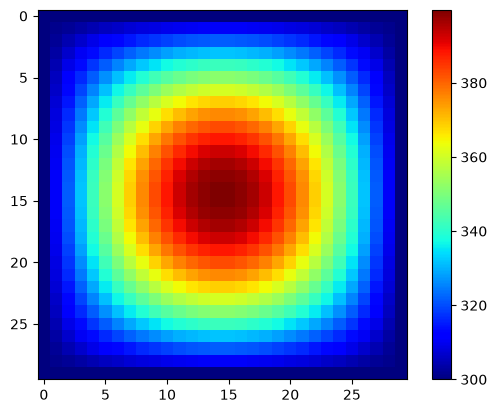

In [45]:
plt.imshow(Temperatura[0], cmap='jet')
plt.colorbar()
plt.show()

In [46]:
for i in range(1, len(t)):
  Temperatura[i,:,:] =  T(X, Y, t[i], **params)

In [47]:
fig = graficar_planos(
    Temperatura, Lx, Ly,
    n_planos=10,
    opacidad=0.5
)
fig.show()

In [49]:
np.shape(Temperatura)

(188, 30, 30)

In [48]:
n_frames =len(Temperatura)# min(100), Temperatura.shape[0])
n_frames

188

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

n_frames =len(Temperatura)# min(100), Temperatura.shape[0])

fig, ax = plt.subplots(figsize=(6, 5))

imagen = ax.imshow(
    Temperatura[0],
    cmap="jet",
    vmin=np.nanmin(Temperatura[:n_frames]),
    vmax=np.nanmax(Temperatura[:n_frames])
)

fig.colorbar(imagen, ax=ax, label="Temperatura [°C]")
titulo = ax.set_title("Temperatura[0]")

def actualizar(i):
    imagen.set_data(Temperatura[i])
    titulo.set_text(f"Temperatura[{i}]")
    return imagen, titulo

animacion = FuncAnimation(
    fig,
    actualizar,
    frames=n_frames,
    interval=1,
    repeat=True
)

plt.close(fig)
display(HTML(animacion.to_jshtml()))


# Physics-Informed Machine Learning (PIML)

Consideremos la ecuación de difusión de calor en dos dimensiones:

$$
\frac{\partial T}{\partial t}
=
\alpha\left(
\frac{\partial^2 T}{\partial x^2}
+
\frac{\partial^2 T}{\partial y^2}
\right),
$$

donde $\alpha$ es la difusividad térmica.

## 1. Modelo neuronal con tangente hiperbólica

Consideremos una neurona definida por:

$$
Z_\theta(x,y,t)=\theta_1 x+\theta_2 y+\theta_3 t+b.
$$

La temperatura se aproxima mediante:

$$
T_\theta(x,y,t)=\tanh(Z_\theta).
$$

## 2. Modelo neuronal con activación gaussiana

Conservando una sola neurona, podemos incorporar una dependencia espacial cuadrática:

$$
Z_\theta(x,y,t)=
\theta_1(x-x_c)^2+
\theta_2(y-y_c)^2+
\theta_3t+b.
$$

La temperatura se aproxima mediante:

$$
T_\theta(x,y,t)=e^{-Z_\theta}.
$$

Esta función permite representar distribuciones localizadas de temperatura, con un máximo espacial cuando los coeficientes cuadráticos son positivos.

## 3. Función de coste física

Para cualquiera de los dos modelos, definimos el residuo:

$$
R_\theta(x_i,y_i,t_i)=
\frac{\partial T_\theta}{\partial t}
-
\alpha\left(
\frac{\partial^2T_\theta}{\partial x^2}
+
\frac{\partial^2T_\theta}{\partial y^2}
\right).
$$

La función de coste es:

$$
J_{\mathrm{fisica}}(\theta)=
\frac{1}{M}\sum_{i=1}^{M}
R_\theta(x_i,y_i,t_i)^2.
$$

Las derivadas se calculan mediante diferenciación automática.

## 4. Condiciones iniciales y de frontera

Si conocemos las temperaturas iniciales y de frontera, incorporamos sus errores:

$$
J(\theta)=
J_{\mathrm{fisica}}
+
J_{\mathrm{inicial}}
+
J_{\mathrm{frontera}}.
$$

Finalmente, los parámetros se actualizan mediante descenso de gradiente:

$$
\theta^{(k+1)}
=
\theta^{(k)}
-\eta\nabla_\theta J.
$$

Ambos modelos tienen cuatro parámetros entrenables: tres pesos y un sesgo. La diferencia principal está en la función utilizada para representar el campo de temperaturas.


Para entrenar la red construiremos un vector de entrada como sigue:
https://www.sciencedirect.com/science/article/pii/S0021999118307125

\begin{equation}
\mathbf Q=
\begin{pmatrix}
x_1&y_1&t_0\\
x_2&y_2&t_0\\
\vdots&\vdots&\vdots\\
x_N&y_N&t_0
\end{pmatrix}
\end{equation}




### Parámetros físicos del problema

| Parámetro | Valor | Significado |
|---|---|---|
| $L_x,\ L_y$ | 1 m | dimensiones de la placa |
| $T_b$ | 300 °C | temperatura fija de los bordes |
| $\Delta T$ | 100 °C | exceso de temperatura inicial en el centro |
| $\alpha$ | $10^{-4}$ m²/s | difusividad térmica |

Se agrupan en el diccionario `params` para pasarlos fácilmente a las funciones.

In [51]:
Lx = 1.0       # Longitud en x [m]
Ly = 1.0       # Longitud en y [m]
Tb = 300     # Temperatura fija de los bordes [°C]
delta_T = 100.0 # Diferencia inicial centro-bordes [°C]

alpha = 1e-4  # Difusividad térmica [m²/s]
params = {'Lx': Lx, 'Ly': Ly, 'Tb': Tb, "delta":delta_T ,'alpha': alpha}

In [52]:
def T(x, y, t, **params):
  Lx = params['Lx']
  Ly = params['Ly']
  Tb = params['Tb']
  alpha = params['alpha']
  u = np.sin(np.pi*x/Lx)*np.sin(np.pi*y/Ly)
  return Tb + delta_T* np.exp(-2*alpha*np.pi**2*t/(Lx*Ly))*u


### Malla de puntos (espacio y tiempo)

Usamos la misma discretización que antes: $30\times30$ puntos en la placa y $n_t = 188$ instantes entre 0 y 500 s.

En la PINN, cada punto $(t, x, y)$ de esta malla será un punto de evaluación de la red. En total $188\times30\times30 = 169\,200$ puntos, que luego separaremos en interior, condición inicial y bordes.

In [53]:
nx, ny = 30, 30
tiempo_final = 500.0

x = np.linspace(0, params["Lx"], nx)
y = np.linspace(0, params["Ly"], ny)
dx = x[1] - x[0]
dy = y[1] - y[0]

# Límite de estabilidad para diferencias finitas con Euler explícito
dt_max = 1 / (
    2 * params["alpha"] * (1 / dx**2 + 1 / dy**2)
)
# Margen de seguridad del 10 %
nt = int(np.ceil(tiempo_final / (0.9 * dt_max))) + 1

t = np.linspace(0, tiempo_final, nt)
dt = t[1] - t[0]
X, Y = np.meshgrid(x, y, indexing="ij")
nx, ny, nt = len(x), len(y), len(t)
Temperatura = np.zeros((nt,nx, ny))

### Información conocida: bordes y condición inicial

`Temp_border` asigna $T_b = 300$ °C a los bordes en todos los instantes y deja el interior en 0.
Luego, solo la primera foto ($t = 0$) se llena con la condición inicial exacta.

Así, `Temperatura` contiene únicamente lo que la PINN conoce del problema:
- **bordes** en todos los tiempos → se usarán en $J_{frontera}$;
- **condición inicial** en $t = 0$ → se usará en $J_{inicial}$.

El interior para $t > 0$ es desconocido (queda en 0 y no se usa como dato): la red debe deducirlo a partir de la ecuación del calor ($J_{física}$).

In [57]:
def Temp_border():
  for k in range(0, nt):
    for i   in range(0, nx):
      for j in range(0, ny):
        if(i == 0):
          Temperatura[k][0, j] = Tb
        elif(j == 0):
          Temperatura[k][i, 0] = Tb
        elif(i == nx-1):
          Temperatura[k][nx-1, j] = Tb
        elif(j == ny-1):
          Temperatura[k][i, ny-1] = Tb
        else:
          Temperatura[k][i, j] = 0
  return Temperatura

In [ ]:
tf = np.max(t) - np.min(t)
tf # Tiempo final

np.float64(500.0)

### Datos conocidos: bordes y condición inicial

Construimos el arreglo `Temperatura` solo con la información que la PINN conoce del problema:

1. **Bordes:** `Temp_border()` fija $T = T_b = 300$ °C en los cuatro lados de la placa, para todos los instantes.
2. **Condición inicial:** la primera foto ($t = 0$) se reemplaza por la solución exacta:
$$T(x,y,0) = T_b + \Delta T\,\sin\!\left(\tfrac{\pi x}{L_x}\right)\sin\!\left(\tfrac{\pi y}{L_y}\right)$$

| Foto | Contenido |
|---|---|
| $t = 0$ | loma de calor: 300 °C en los bordes, ≈400 °C en el centro |
| $t > 0$ | 300 °C en los bordes, interior desconocido (en 0) |

El interior para $t > 0$ es lo que la red debe aprender usando la ecuación del calor.



In [56]:
#x = np.linspace(0, 1, 100)
#y = np.linspace(0, 1, 100)
#t = np.linspace(0, 800, 1000)
X, Y = np.meshgrid(x, y, indexing="ij")
Temperatura = Temp_border()
Temperatura[0,:,:] =  T(X, Y, 0, **params)


In [59]:
X1 = x.reshape((len(x), 1))
Y1 = y.reshape((len(y), 1))
tk = t.reshape((len(t), 1))/np.max(t)

### Matriz de puntos de evaluación $\mathbf{Q}$

Construimos una tabla con todos los puntos de la malla espacio-temporal, uno por fila:

$$
\mathbf{Q} =
\begin{pmatrix}
t_0 & x_0 & y_0\\
t_0 & x_0 & y_1\\
\vdots & \vdots & \vdots\\
t_{n_t-1} & x_{n_x-1} & y_{n_y-1}
\end{pmatrix},
\qquad \text{forma } (n_t\, n_x\, n_y,\ 3) = (169\,200,\ 3).
$$




In [60]:
Q=np.zeros((30*30*nt, 3))
p=0
for k in range(0, nt):
  for i in range(0, nx):
    for j in range(0, ny):
      Q[p] = np.array([ t[k],x[i], y[j]])
      p=p+1

### Selección de los puntos de borde

1. Separamos las columnas de $\mathbf{Q}$ y les damos forma $(n_t, n_x, n_y)$, para tener las coordenadas $t$, $x$, $y$ de cada punto en la misma forma que `Temperatura`.
2. Construimos una **máscara booleana**: un punto es borde si $x = 0$, $x = L_x$, $y = 0$ o $y = L_y$ 
3. Aplanamos la máscara con `reshape(-1)` para que tenga el mismo orden que las filas de $\mathbf{Q}$.

En cada instante hay $4\cdot30 - 4 = 116$ puntos de borde, es decir, $116\times188 = 21\,808$ en total.

In [61]:
tt = Q[:,0].reshape(nt, nx, ny)
xx = Q[:,1].reshape(nt, nx, ny)
yy = Q[:,2].reshape(nt, nx, ny)
borde = (
    np.isclose(xx, x[0]) |
    np.isclose(xx, x[-1]) |
    np.isclose(yy, y[0]) |
    np.isclose(yy, y[-1])
)
borde_concatenado = borde.reshape(-1)

In [62]:
Q_borde = Q[borde_concatenado]
Q_borde

array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 3.44827586e-02],
       [0.00000000e+00, 0.00000000e+00, 6.89655172e-02],
       ...,
       [5.00000000e+02, 1.00000000e+00, 9.31034483e-01],
       [5.00000000e+02, 1.00000000e+00, 9.65517241e-01],
       [5.00000000e+02, 1.00000000e+00, 1.00000000e+00]], shape=(21808, 3))

In [63]:
T_borde = Temperatura[borde].reshape(-1, 1)
print(Q_borde.shape)
print(T_borde.shape)

(21808, 3)
(21808, 1)


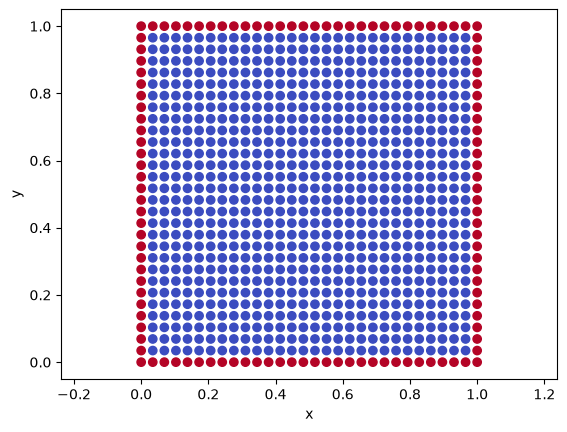

In [64]:
plt.scatter(xx[0], yy[0], c=borde[0], cmap="coolwarm")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.show()

## Condición inicial

Seleccionamos los puntos de $\mathbf{Q}$ con $t = t_0 = 0$ mediante una máscara booleana, y extraemos sus temperaturas de la foto inicial:

- `Q_ini`: coordenadas $(t, x, y)$ de los $30\times30 = 900$ puntos en $t = 0$ → forma $(900, 3)$.
- `T_ini`: temperatura conocida en cada uno de esos puntos → forma $(900, 1)$.

Estos pares (punto, temperatura) se usarán en el término $J_{inicial}$ de la función de coste.

In [65]:
inicial = np.isclose(tt, t[0])
Q_ini = Q[inicial.reshape(-1)]
T_ini = Temperatura[inicial].reshape(-1, 1)
print(Q_ini.shape)
print(T_ini.shape)

(900, 3)
(900, 1)


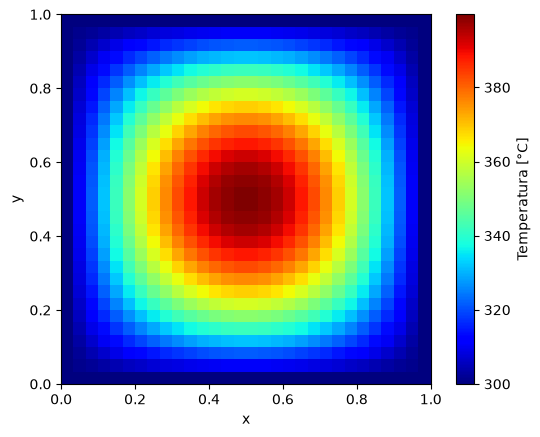

In [66]:
plt.imshow(
    Temperatura[0].T,
    origin="lower",
    extent=[x[0], x[-1], y[0], y[-1]],
    cmap="jet"
)

plt.colorbar(label="Temperatura [°C]")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [67]:
#Normalizacion
delta_T = max(np.max(np.abs(T_ini - Tb)), 1.0)
u_ini = (T_ini - Tb) / delta_T
u_borde = (T_borde - Tb) / delta_T

In [68]:
interior = ~borde & ~inicial

Q_f = Q[interior.reshape(-1)]

### Entrenamiento del modelo con tanh

**Modelo:** $Z = w_t\,t + w_x\,x + w_y\,y + b$, y la temperatura normalizada se aproxima como $u_\theta = \tanh(Z)$.

En cada iteración se realizan los siguientes pasos:

1. **Evaluación de la red.** Se calcula la salida de la neurona en todos los puntos interiores: $Z = \mathbf{Q}_f\,W + b$ y $A = \tanh(Z)$.

2. **Derivadas de la red.** Con diferenciación automática (`tanhiperbolica2`) se obtienen las derivadas de la red respecto a $t$, $x$ e $y$. La semilla de cada derivada es el peso de esa variable, porque $\partial Z/\partial t = w_t$, $\partial Z/\partial x = w_x$ y $\partial Z/\partial y = w_y$:
$$\partial_t A = (1-A^2)\,w_t, \qquad \partial_{xx} A = -2A(1-A^2)\,w_x^2.$$

3. **Error físico.** Se sustituyen las derivadas en la ecuación del calor para obtener el residuo $R = \partial_t A - \alpha\,(\partial_{xx}A + \partial_{yy}A)$. El error físico es el promedio de $R^2$ sobre los puntos interiores.

4. **Gradiente del error físico.** Se calcula cómo cambia $R$ al variar cada parámetro. Los pesos aparecen de dos formas en $R$: dentro de $Z$ (término `C*dZ`) y como factores explícitos ($w_t$, $w_x^2$, $w_y^2$), que se suman aparte en las correcciones `dR[:, k]`.

5. **Error en la condición inicial y en los bordes.** Se compara la salida de la red con los valores conocidos (`u_ini` y `u_borde`) mediante el error cuadrático medio, y se suma su gradiente al gradiente total.

6. **Actualización de los parámetros.** Se suman los tres errores, $J = J_{física} + J_{ini} + J_{borde}$, y se actualizan los pesos y el sesgo con descenso de gradiente: $\theta \leftarrow \theta - \eta\,\nabla_\theta J$.

`dZ` contiene las derivadas de $Z$ respecto a los parámetros, $(t,\ x,\ y,\ 1)$, para cada punto.



In [69]:
# Inicialización
np.random.seed(42)

perdidas = []
eta = 0.01

W = np.random.random((3, 1))
B = np.random.random((1, 1))

# Derivadas de Z respecto a (wt, wx, wy, b)
dZ = np.column_stack((Q_f, np.ones(len(Q_f))))
dZ_ini = np.column_stack((Q_ini, np.ones(len(Q_ini))))
dZ_borde = np.column_stack((Q_borde, np.ones(len(Q_borde))))

et = np.array([1, 0, 0, 0])

for i in range(1000):
    if(i%50==0):
      print(i)

    # Forward
    Z = Q_f @ W + B
    A = np.tanh(Z)

    # Derivadas
    _, dA_dt, _ = tanhiperbolica2(Z, W[0, 0], 0)
    _, _, d2A_dx2 = tanhiperbolica2(Z, W[1, 0], 0)
    _, _, d2A_dy2 = tanhiperbolica2(Z, W[2, 0], 0)
    R = dA_dt - alpha * (d2A_dx2 + d2A_dy2)
    J_fisica = np.mean(R**2)

    # Derivadas de tanh respecto a Z
    A, G, H = tanhiperbolica2(Z, 1, 0)
    _, K = producto(-2*A, -2*G, G, H)

    # Pesos
    wt, wx, wy = W[:, 0]

    # Gradientes del residuo
    C = wt*H - alpha*(wx**2 + wy**2)*K

    dR = C*dZ

    dR[:, 0] += G[:, 0]
    dR[:, 1] -= 2*alpha*wx*H[:, 0]
    dR[:, 2] -= 2*alpha*wy*H[:, 0]

    # Gradiente de la función de coste
    gradiente = np.mean(2*R*dR, axis=0)

    # Condición inicial
    A_ini = np.tanh(Q_ini @ W + B)
    J_ini = np.mean((A_ini - u_ini)**2)
    ei = (A_ini - u_ini) * (1 - A_ini**2)
    gradiente += 2*np.mean(ei*dZ_ini, axis=0)

    # Condiciones de frontera
    A_borde = np.tanh(Q_borde @ W + B)
    J_borde = np.mean((A_borde - u_borde)**2)
    eb = (A_borde - u_borde) * (1 - A_borde**2)
    gradiente += 2*np.mean(eb*dZ_borde, axis=0)

    # Función de coste total
    J = J_fisica + J_ini + J_borde

    # Actualización de los parámetros
    W[:, 0] -= eta * gradiente[:3]
    B[0, 0] -= eta * gradiente[3]

    perdidas.append(J)

0
50
100
150
200
250
300
350
400
450
500
550
600
650
700
750
800
850
900
950


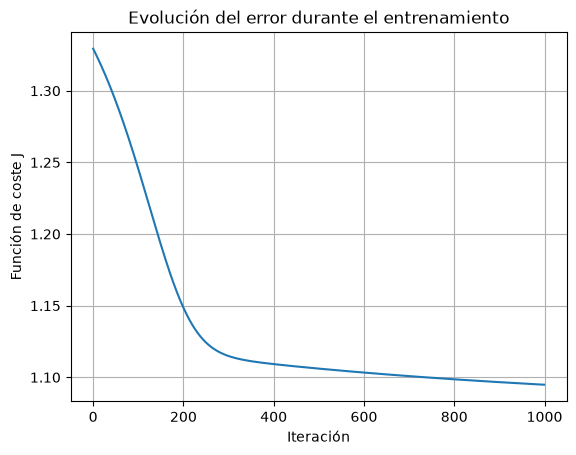

In [70]:
plt.plot(np.array(perdidas))
plt.xlabel("Iteración")
plt.ylabel("Función de coste J")
plt.title("Evolución del error durante el entrenamiento")
plt.grid()
plt.show()



Se grafica el valor de $J$ en cada iteración. Si el entrenamiento funciona, la curva debe bajar y estabilizarse cerca de cero. Sine embargo vemos que no es así $J$ baja solo de ≈1.33 a ≈1.09: el modelo con tanh no logra ajustarse a las condiciones del problema.

### Predicción de la PINN

Evaluamos la red entrenada en todos los puntos de $\mathbf{Q}$ y deshacemos la normalización para obtener la temperatura en °C:

$$T_{PINN} = T_b + \Delta T\cdot\tanh(\mathbf{Q}\,W + b).$$

El resultado se reorganiza con forma $(n_t, n_x, n_y)$ para poder compararlo con la solución analítica.

In [71]:
Z = Q@W+B
A = np.tanh(Z)
Temperatura_PINN = Tb + delta_T*A.reshape(nt, nx, ny)


In [72]:
A = A.reshape(nx, ny,nt)

In [73]:

fig = graficar_planos(
    Temperatura_PINN,
    Lx,
    Ly,
    tiempos=t,
    n_planos=5
)

fig.show()

De este gráfico se observa que el modelo con tanh no reproduce la solución:

- En $t = 0$ produce un degradado lineal (≈310–360 °C) en lugar de una distribución con máximo en el centro, porque $\tanh$ de una función lineal en $x$ e $y$ solo puede variar en una dirección.
- Para $t > 0$ la placa queda uniformemente a ≈400 °C: como el tiempo no está normalizado, $Z$ toma valores grandes y la tanh se satura ($\tanh Z \approx 1$).
- La red predice que la placa se calienta y no respeta la temperatura de los bordes (300 °C), lo contrario de la solución física.

Para corregirlo, el siguiente modelo normaliza las variables y usa una activación gaussiana con términos cuadráticos $(x - x_c)^2$ y $(y - y_c)^2$.

## Modelo 2: neurona con activación gaussiana

Implementamos el mismo procedimiento para una función de la forma:

$$
u_\theta(\tau,\xi,\eta) = e^{-Z}, \qquad Z = w_t\,\tau + w_x\,\xi^2 + w_y\,\eta^2 + b,
$$

donde las variables están **normalizadas**:

$$
\tau = \frac{t - t_0}{t_f} \in [0, 1], \qquad
\xi = \frac{x}{L_x} - 0.5, \qquad
\eta = \frac{y}{L_y} - 0.5 \in [-0.5,\ 0.5].
$$

**Diferencias con el modelo de tanh:**
- **Tiempo normalizado:** $\tau$ va de 0 a 1, así que $Z$ no crece demasiado y la red no se satura.
- **Términos cuadráticos centrados:** $\xi^2$ y $\eta^2$ valen 0 en el centro de la placa y crecen hacia los bordes. Con $w_x, w_y > 0$, $e^{-Z}$ es máxima en el centro, es decir, una campana.
- **Enfriamiento:** con $w_t > 0$, $Z$ crece con el tiempo y $e^{-Z}$ disminuye, así que la placa se enfría.

Al cambiar de variables, la ecuación del calor queda:

$$
\frac{\partial u}{\partial \tau} = a_x\,\frac{\partial^2 u}{\partial \xi^2} + a_y\,\frac{\partial^2 u}{\partial \eta^2},
\qquad a_x = \frac{\alpha\, t_f}{L_x^2},\quad a_y = \frac{\alpha\, t_f}{L_y^2}.
$$

In [74]:
def caracteristicas(Q):
    tau = (Q[:, 0:1] - t[0]) / tf
    xi = (Q[:, 1:2] - x[0]) / Lx - 0.5
    yi = (Q[:, 2:3] - y[0]) / Ly - 0.5

    P = np.hstack((tau, xi**2, yi**2))

    return P, xi, yi

P, xi, yi = caracteristicas(Q)
P_ini, _, _ = caracteristicas(Q_ini)
P_borde, _, _ = caracteristicas(Q_borde)

In [75]:
W = np.random.random((3, 1))
B = np.random.random((1, 1))

Z = P @ W + B
A = np.exp(-Z)

In [76]:
def exponencial(a, da):
    A = np.exp(a)
    return A, A*da

def exponencial2(a, da, d2a):
    A, dA = exponencial(a, da)
    _, d2A = producto(A, dA, da, d2a)
    return A, dA, d2A

In [77]:
wt, wx, wy = W[:, 0]

_, dA_dt, _ = exponencial2(-Z, -wt, 0)

_, _, d2A_dx2 = exponencial2(
    -Z, -2*wx*xi, -2*wx
)

_, _, d2A_dy2 = exponencial2(
    -Z, -2*wy*yi, -2*wy
)

In [78]:
ax = alpha * tf / Lx**2
ay = alpha * tf / Ly**2

R = dA_dt - ax*d2A_dx2 - ay*d2A_dy2

J_fisica = np.mean(R**2)

In [ ]:
np.random.seed(42)

W = np.random.random((3, 1)) # Dado que W solo tiene una columna, esto corresponde a una sola neurona.
B = np.random.random((1, 1))

eta = 0.01
perdidas = []

ax = alpha * tf / Lx**2
ay = alpha * tf / Ly**2

dZ = np.column_stack((P, np.ones(len(P))))
dZ_ini = np.column_stack((P_ini, np.ones(len(P_ini))))
dZ_borde = np.column_stack((P_borde, np.ones(len(P_borde))))

et, ex, ey = np.eye(4)[:3]

for i in range(1000):

    # Forward
    Z = P @ W + B
    A = np.exp(-Z)

    wt, wx, wy = W[:, 0]

    # Derivadas automáticas respecto a las coordenadas
    _, dA_dt, _ = exponencial2(-Z, -wt, 0)

    _, _, d2A_dx2 = exponencial2(
        -Z, -2*wx*xi, -2*wx
    )

    _, _, d2A_dy2 = exponencial2(
        -Z, -2*wy*yi, -2*wy
    )

    R = dA_dt - ax*d2A_dx2 - ay*d2A_dy2
    J_fisica = np.mean(R**2)

    # Gradientes del residuo respecto a W y B
    px, dpx = producto(2*xi, 0, wx, ex)
    py, dpy = producto(2*yi, 0, wy, ey)

    Fx, dFx = producto(px, dpx, px, dpx)
    Fx, dFx = suma(Fx, dFx, -2*wx, -2*ex)

    Fy, dFy = producto(py, dpy, py, dpy)
    Fy, dFy = suma(Fy, dFy, -2*wy, -2*ey)

    C, dC = suma(-wt, -et, -ax*Fx, -ax*dFx)
    C, dC = suma(C, dC, -ay*Fy, -ay*dFy)

    _, dR = producto(A, -A*dZ, C, dC)

    gradiente = np.mean(2*R*dR, axis=0)

    # Condición inicial
    A_ini = np.exp(-(P_ini @ W + B))

    J_ini = np.mean((A_ini - u_ini)**2)

    ei = (A_ini - u_ini) * (-A_ini)
    gradiente += 2*np.mean(ei*dZ_ini, axis=0)

    # Condición de frontera
    A_borde = np.exp(-(P_borde @ W + B))

    J_borde = np.mean((A_borde - u_borde)**2)

    eb = (A_borde - u_borde) * (-A_borde)
    gradiente += 2*np.mean(eb*dZ_borde, axis=0)

    # Coste total
    J = J_fisica + J_ini + J_borde
    perdidas.append(J)

    # Actualizar parámetros
    W[:, 0] -= eta*gradiente[:3]
    B[0, 0] -= eta*gradiente[3]

    if i % 50 == 0:
        print(i, J)

0 0.20794333370467535
50 0.16953420784536372
100 0.1524483378853501
150 0.14333168240336175
200 0.13790447188370886
250 0.13442161282876935
300 0.13205678759894374
350 0.13037641605880035
400 0.12913526140946585
450 0.12818644528168052
500 0.12743794867553102
550 0.12682999497542846
600 0.1263225822810427
650 0.12588827265537395
700 0.12550785111114748
750 0.1251676218979046
800 0.12485767476402859
850 0.12457074481608288
900 0.12430144606265492
950 0.12404574611832306


In [80]:
A = np.exp(-(P @ W + B))

Temperatura_PINN = Tb + delta_T*A.reshape(nt, nx, ny)

fig = graficar_planos(
    Temperatura_PINN,
    Lx,
    Ly,
    tiempos=t,
    n_planos=5
)

fig.show()

Se observa que con una función de activación gaussiana, el modelo logra recrear muy bien la evolución temporal de la temperatura.

El modelo reproduce el comportamiento cualitativo de la solución:
- la temperatura es máxima en el centro y menor hacia los bordes;
- la placa se enfría con el tiempo.

Sin embargo, los valores no coinciden con la solución analítica: en $t = 0$ el centro está a ≈333 °C (en lugar de 400 °C) y los bordes a ≈320 °C (en lugar de 300 °C).

Esto se debe a que:
1. una sola neurona gaussiana no puede reproducir exactamente la forma $\sin(\pi x)\sin(\pi y)$ de la solución real;
2. la red debe equilibrar tres términos de error ($J_{física}$, $J_{ini}$, $J_{borde}$) y encuentra un compromiso entre ellos;
3. el entrenamiento no ha convergido completamente en 1000 iteraciones.

Aun así, comparado con el modelo de tanh, la normalización de las variables y la forma gaussiana permiten capturar la física del problema.
